In [1]:
import numpy as np
import re
import math
import sys
from collections import defaultdict, Counter
import json
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])

modification_data = {
    'short_across_traces': [31, 32, 33, 34, 35],
    'short_within_trace': [26, 27, 28, 29, 30],
    'open': [21, 22, 23, 24, 25],
}

def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen
            _rest, _, serial = specimen.rpartition('-')
            try:
                serial = int(serial)
            except:
                serial = 'none'

            mods = []
            for modification, matching_serials in modification_data.items():
                if serial in matching_serials:
                    mods.append(modification)
            info['mods'] = mods

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = '?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            info['pitch'] = pitch
            info['serial'] = serial if serial != 'none' else 0
            data_dict[mesh_id].append(data)
    return data_dict

data = load_multichannel_data()

/tmp/ipykernel_794449/2647136726.py:40: UserWarning: Unknown pitch for 'cal-open'
  warnings.warn(f'Unknown pitch for {meta!r}')
/tmp/ipykernel_794449/2647136726.py:40: UserWarning: Unknown pitch for 'baseline-5-open'
  warnings.warn(f'Unknown pitch for {meta!r}')


In [3]:
{key: value[0]['info'].get('mods') for key, value in data.items()}

{'M-SP-PITCH-V2-0100-0.3': [],
 'M-SP-PITCH-V2-0097-0.3': [],
 'M-SP-PITCH-V2-0096-0.3': [],
 'M-SP-PITCH-V2-0099-0.3': [],
 'M-SP-PITCH-V2-0098-0.3': [],
 'M-SP-PITCH-V2-0095-0.3': [],
 'M-SP-PITCH-V2-0094-0.3': [],
 'M-SP-PITCH-V2-0093-0.3': [],
 'M-SP-PITCH-V2-0092-0.3': [],
 'M-SP-PITCH-V2-0091-0.3': [],
 'M-SP-PITCH-V2-0090-0.3': [],
 'M-SP-PITCH-V2-0089-0.3': [],
 'M-SP-PITCH-V2-0088-0.3': [],
 'M-SP-PITCH-V2-0087-0.3': [],
 'M-SP-PITCH-V2-0086-0.3': [],
 'M-SP-PITCH-V2-0085-0.3': [],
 'M-SP-PITCH-V2-0084-0.3': [],
 'M-SP-PITCH-V2-0083-0.3': [],
 'M-SP-PITCH-V2-0082-0.3': [],
 'M-SP-PITCH-V2-0081-0.3': [],
 'M-SP-PITCH-V2-0080-0.3': [],
 'M-SP-PITCH-V2-0079-0.3': [],
 'M-SP-PITCH-V2-0078-0.3': [],
 'M-SP-PITCH-V2-0077-0.3': [],
 'M-SP-PITCH-V2-0076-0.3': [],
 'M-SP-PITCH-V2-0075-0.3': [],
 'M-SP-PITCH-V2-0074-0.3': [],
 'M-SP-PITCH-V2-0073-0.3': [],
 'M-SP-PITCH-V2-0072-0.3': [],
 'M-SP-PITCH-V2-0071-0.3': [],
 'M-SP-PITCH-V2-0070-0.3': [],
 'M-SP-PITCH-V2-0069-0.3': [],
 'M-SP-P

In [4]:
Counter([value['info']['meta'] for entries in data.values() for value in entries])

Counter({'Baseline-2-p0.3': 100,
         'Baseline-1-p0.3': 30,
         'Baseline-2-p0.4': 30,
         'Baseline-1-p0.4': 25,
         'mods-25-07-01-01-p0.3': 16,
         'mods-25-07-01-01-p0.4': 16,
         'baseline-4-p0.4': 15,
         'mods-25-07-01-01-p0.6': 15,
         'mods-25-07-01-01-p1.0': 15,
         'baseline-4-p0.3': 10,
         'Baseline-2-alt-side-a-right-p0.4': 10,
         'Baseline-1-alt-side-a-right-p0.4': 10,
         'Baseline-2-alt-side-a-left-p0.4': 10,
         'Baseline-1-alt-side-a-left-p0.4': 10,
         'baseline-6-p0.6': 10,
         'baseline-6-p1.0': 10,
         'mod-25-07-02-01-p0.3': 6,
         'baseline-5-p0.6': 2,
         'cal-open': 1,
         'baseline-5-open': 1,
         'baseline-4-p0.6': 1})

In [5]:
[value['info'] for entries in data.values() for value in entries if value['info']['meta'] == 'mods-25-07-01-01-p0.3']

[{'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0035',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:35.483Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0035-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 35},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0034',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:55.114Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0034-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 34},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0033',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:29:13.962Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0033-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 33},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PI

In [78]:
def newest_for_mesh(chip='pi3hdx12211'):
    out = {}
    for key, entries in data.items():
        entries = [e for e in entries if e['info']['chip'] == chip]
        out[key] = entries[0]
        for value in entries[1:]:
            if value['info']['timestamp'] > out[key]['info']['timestamp']:
                out[key] = value
    return out

data_newest = newest_for_mesh()
mod_baseline = {pitch: [
                        data_newest[f'M-SP-PITCH-V2-{serial:04d}-{pitch}']
                        for serial in [1,2,3,4,5]]
                for pitch in [0.3, 0.4, 0.6, 1.0]}

mod_modified = {(mod, pitch): [
                        value
                        for value in data_newest.values()
                        if mod in value['info']['mods']
                        and value['info']['pitch'] == str(pitch)]
                for mod, pitch in itertools.product(['open', 'short_within_trace', 'short_across_traces'],
                                                    [0.3, 0.4, 0.6, 1.0])}
one_specimen_baseline = {pitch:
                         [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == f'M-SP-PITCH-V2-0005-{pitch}'][-5:]
                         for pitch in [0.3, 0.4, 0.6, 1.0]}

#{k: [e['info']['timestamp'] for e in v] for k, v in mod_baseline.items()}
#{k: [e['info']['meta'] for e in v] for k, v in mod_modified.items()}
{k: [e['info']['timestamp'] for e in v] for k, v in one_specimen_baseline.items()}

{0.3: ['2025-06-27T14:34:51.238Z', '2025-07-01T13:00:21.356Z'],
 0.4: ['2025-06-27T14:48:51.116Z',
  '2025-06-27T14:50:14.712Z',
  '2025-06-27T14:51:49.996Z',
  '2025-06-27T14:53:07.147Z',
  '2025-07-01T13:03:55.562Z'],
 0.6: ['2025-07-01T13:08:49.451Z', '2025-07-01T13:19:55.971Z'],
 1.0: ['2025-07-01T13:20:32.218Z']}

In [7]:
len([val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:])
len(list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values()))

5

Baseline threshold set at 0.999976
Within class: 1±9.66e-06 max: 1
Cross class: 1±3.37e-05 max: 1
Baseline false negative probability: 0.055268299027
Baseline false positive probability: 0.323891986799


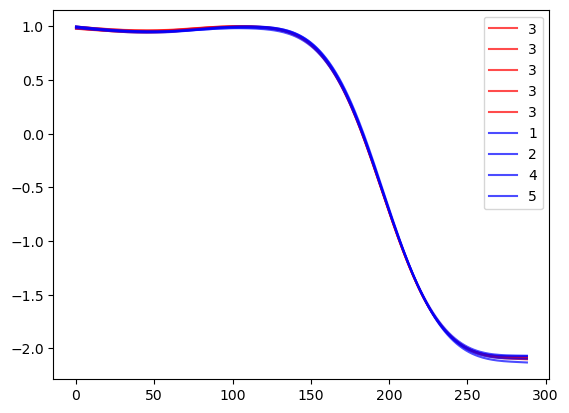

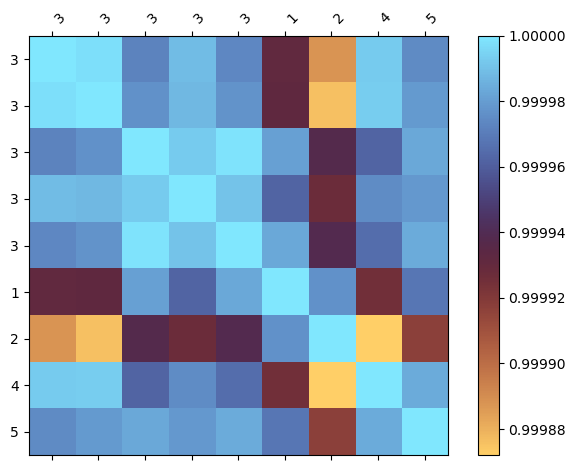

In [130]:
roi_map = {
    'tdp0604': (155, 445),
    'pi3hdx12211': (160, 450),
}
foo = list(roi_map.values())[0]
roi_n = foo[1] - foo[0]

def plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), roi_n))
    labels = []
    for i, trace in enumerate(all_traces):
        trace_data = trace['data'][select_trace][select_channel]
        start, end = roi_map[trace['info']['chip']]
        trace_data = trace_data[start:end]

        if smooth is not None:
            t = np.linspace(0, 1, len(trace_data))
            spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
            trace_data = spl(t)
        
        d[i] = trace_data
        labels.append(str(trace['info']['serial']))
        
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,1:]
    deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    deltas /= np.repeat(deltas.max(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]
    
    corr = np.corrcoef(deltas)
    
    fig, ax = plt.subplots()
    for i, (x, lab) in enumerate(zip(deltas, labels)):
        ax.plot(x, label=lab, color=('red' if i<len(group_a) else 'blue'), alpha=0.7)
    ax.legend()
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())
#plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None)

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
plot_covar(group_a, group_b, select_trace='open_fwd', smooth=1e-2)

Baseline threshold set at 0.970044
Within class: 0.981±0.0138 min: 0.969 max: 1
Cross class: 0.97±0.00108 min: 0.968 max: 0.972
Baseline false negative probability: 0.223542238074
Baseline false positive probability: 0.346638143792


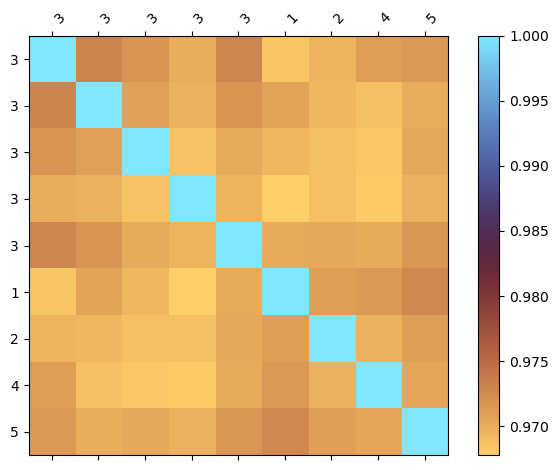

In [112]:
def plot_vector_covar(group_a, group_b, do_cal=False, vector_method='norm', distance_method='corr', smooth=None):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), 12, roi_n))
    labels = []
    for i, entry in enumerate(all_traces):
        start, end = roi_map[entry['info']['chip']]
        labels.append(entry['info']['serial'])
        for j, (term, direction, channel) in enumerate(itertools.product(['open', 'short', 'load'], ['fwd', 'flip'], ['adc1', 'adc2'])):
            trace_data = np.array(entry['data'][f'{term}_{direction}'][channel])
            if do_cal:
                trace_data -= np.array(entry['data']['cal'][channel])
                
            if smooth is not None:
                t = np.linspace(0, 1, len(trace_data))
                spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
                trace_data = spl(t)
            
            d[i, j] = trace_data[start:end]
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,:,1:]
    deltas -= np.repeat(deltas.mean(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    deltas /= np.repeat(deltas.max(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]

    corr = np.zeros((12, len(all_traces), len(all_traces)))
    for i in range(12):
        if distance_method == 'corr':
            corr[i] = np.corrcoef(deltas[:,i,:])
        elif distance_method == 'max':
            for k, l in itertools.product(range(len(all_traces)), repeat=2):
                corr[i, k, l] = 1 - np.abs(deltas[k,i,:] - deltas[l,i,:]).max()
        else:
            raise ValueError(f'invalid distance_method {distance_method!r}')

    if vector_method == 'norm':
        corr = np.sqrt(np.mean(np.square(corr), axis=0))
    elif vector_method == 'min':
        corr = np.min(corr, axis=0)
    else:
        raise ValueError(f'invalid vector_method {vector_method!r}')
    
    within_class = corr[:len(group_a), :len(group_a)][np.triu_indices(len(group_a))]
    cross_class = corr[len(group_a):, :len(group_a)].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    #threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    #threshold = np.mean(within_class) -2*np.std(within_class)
    threshold = (np.min(within_class) + np.max(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} min: {np.min(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b, distance_method='corr', smooth=None)

## Can we distinguish one specimen from other specimens with the same layout?

Baseline threshold set at 0.879568
Within class: 0.918±0.0591 min: 0.858 max: 1
Cross class: 0.873±0.0174 min: 0.835 max: 0.901
Baseline false negative probability: 0.260243544132
Baseline false positive probability: 0.346064417881


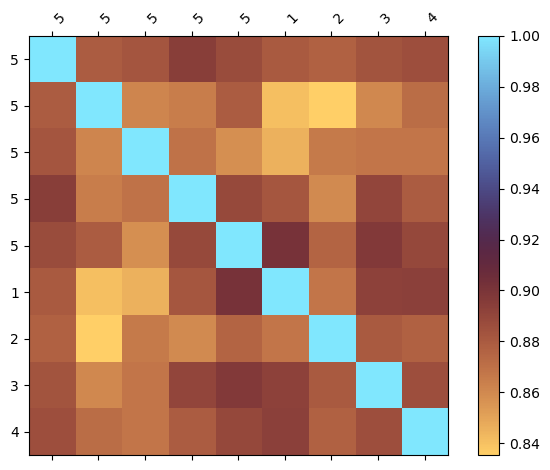

In [80]:
group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0005-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1234]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b)

## Can we distinguish mesh layout variants?

Compare measurements of five specimens of the base layout against measurements of each of the four alternate layouts.

Baseline threshold set at 0.827073
Within class: 0.924±0.0545 min: 0.868 max: 1
Cross class: 0.692±0.0833 min: 0.54 max: 0.787
Baseline false negative probability: 0.037826404995
Baseline false positive probability: 0.052920193073


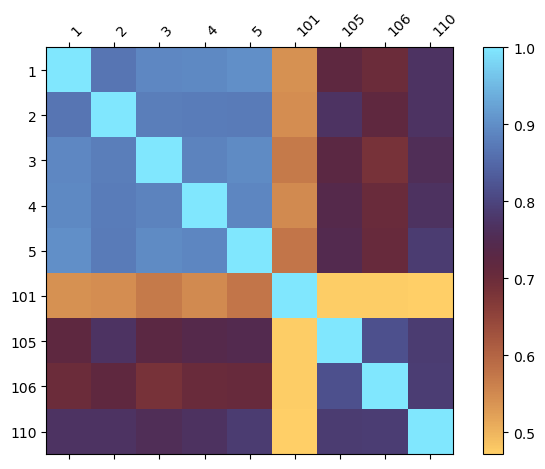

In [81]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b)

#### Same measurement, but show TPD0604 data 

Baseline threshold set at 0.986288
Within class: 0.993±0.00523 min: 0.986 max: 1
Cross class: 0.954±0.0508 min: 0.86 max: 0.987
Baseline false negative probability: 0.101194547713
Baseline false positive probability: 0.261285785973


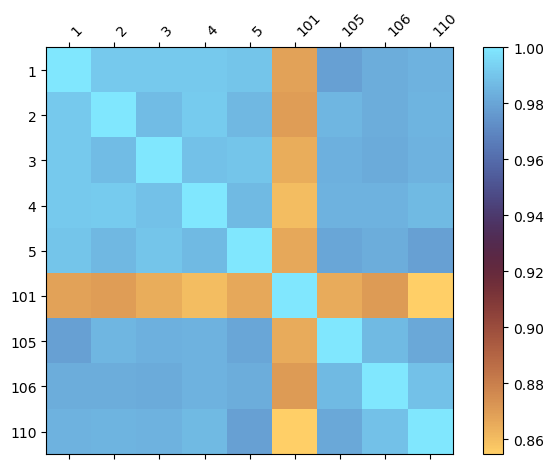

In [82]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, do_cal=False)

Baseline threshold set at 0.565860
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.182±0.0369 min: 0.107 max: 0.25
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


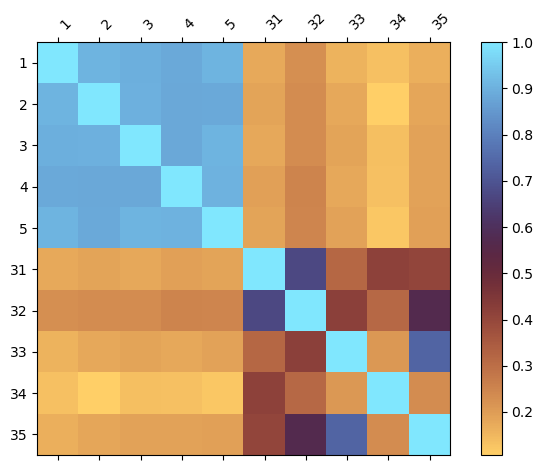

In [83]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.3])

Baseline threshold set at 0.544281
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.171±0.0227 min: 0.121 max: 0.207
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


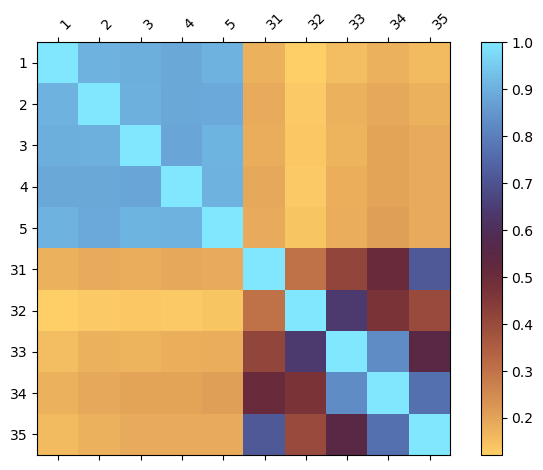

In [84]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.4])

Baseline threshold set at 0.561276
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.116±0.061 min: 0.0208 max: 0.241
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


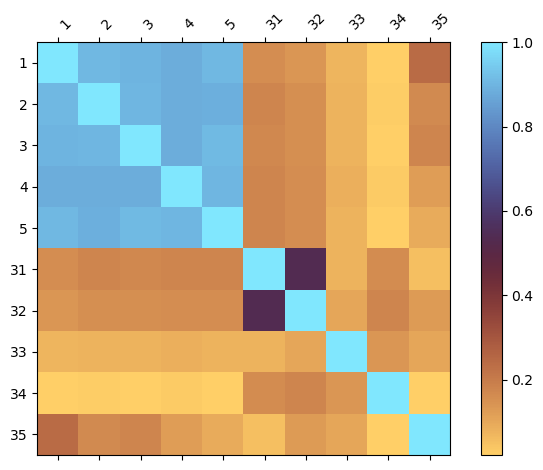

In [85]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.6])

Baseline threshold set at 0.509996
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.0977±0.038 min: 0.0209 max: 0.138
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


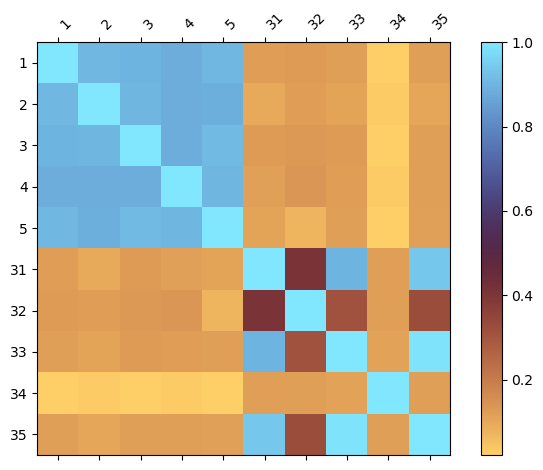

In [86]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 1.0])

Baseline threshold set at 0.555943
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.102±0.0689 min: 0.0291 max: 0.23
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000022


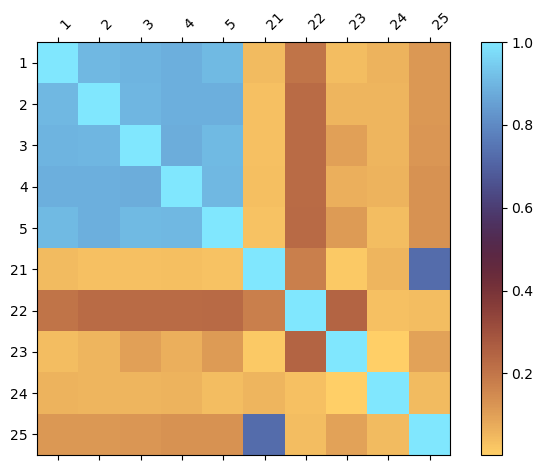

In [87]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.3])

Baseline threshold set at 0.538086
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.128±0.0696 min: 0.00456 max: 0.195
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000001900


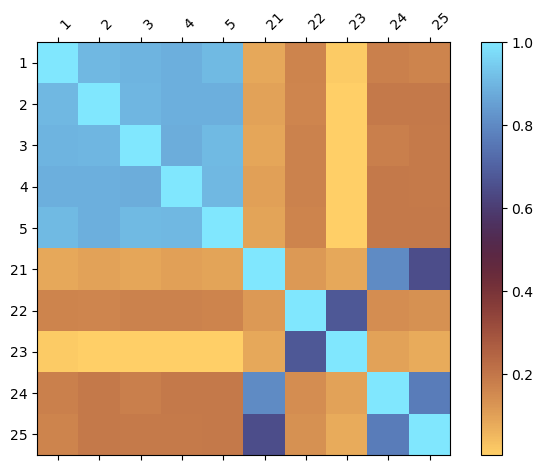

In [88]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.4])

Baseline threshold set at 0.573281
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.0759±0.0777 min: 0.000154 max: 0.265
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000076


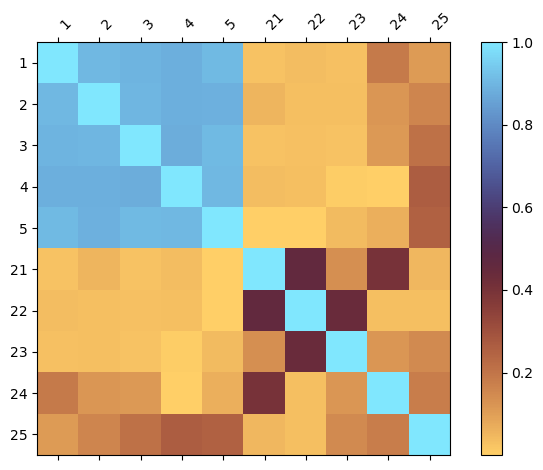

In [89]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.6])

Baseline threshold set at 0.494175
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.0686±0.031 min: 0.00214 max: 0.107
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


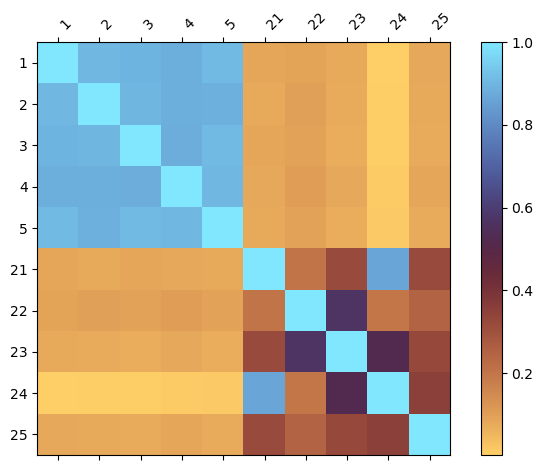

In [90]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 1.0])

Baseline threshold set at 0.998142
Within class: 1±0.000414 min: 0.999 max: 1
Cross class: 0.964±0.0593 min: 0.845 max: 0.998
Baseline false negative probability: 0.000379596973
Baseline false positive probability: 0.284469837306


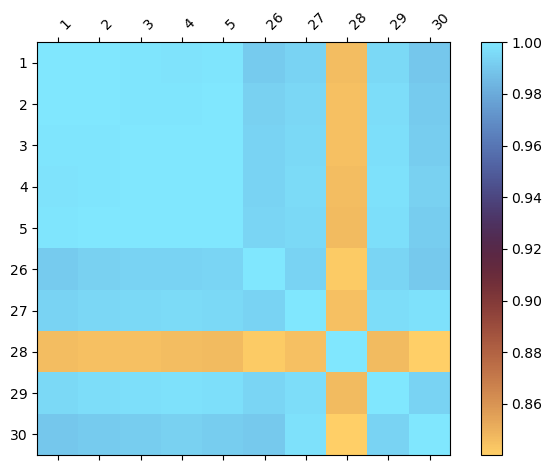

In [150]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], distance_method='corr', vector_method='norm', smooth=1e-5)

Baseline threshold set at 0.963901
Within class: 0.999±0.000926 max: 1
Cross class: 0.929±0.152 max: 1
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.408242946674


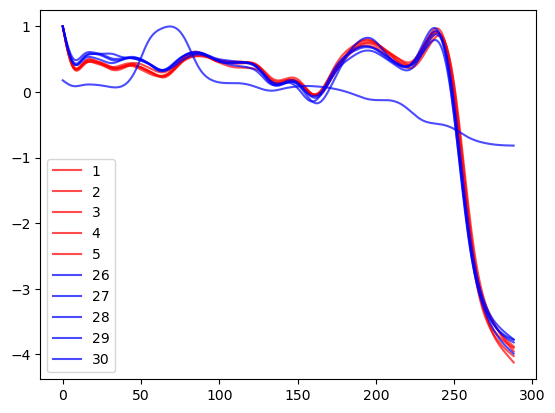

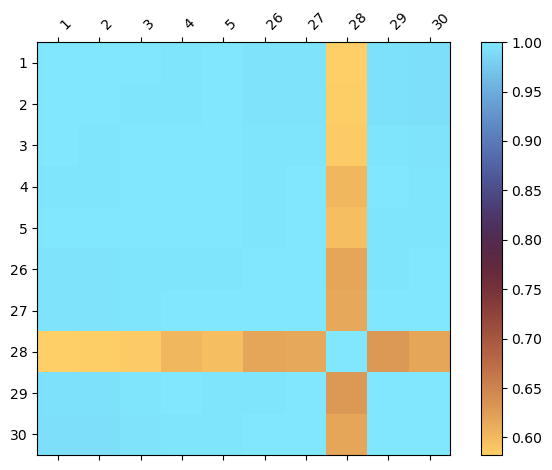

In [144]:
plot_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], select_trace='open_fwd', select_channel='adc1', smooth=1e-5)

Baseline threshold set at 0.682580
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.334±0.116 min: 0.18 max: 0.484
Baseline false negative probability: 0.000000286841
Baseline false positive probability: 0.001286337942


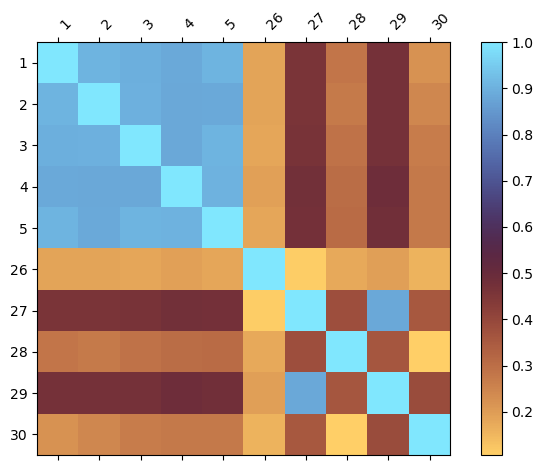

In [92]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.4])

Baseline threshold set at 0.537074
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.0578±0.0439 min: 0.00119 max: 0.193
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


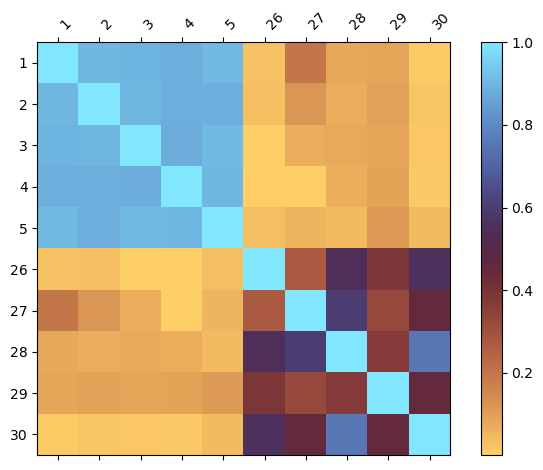

In [93]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.6])

Baseline threshold set at 0.487366
Within class: 0.931±0.0496 min: 0.882 max: 1
Cross class: 0.0534±0.0268 min: 0.00415 max: 0.0931
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


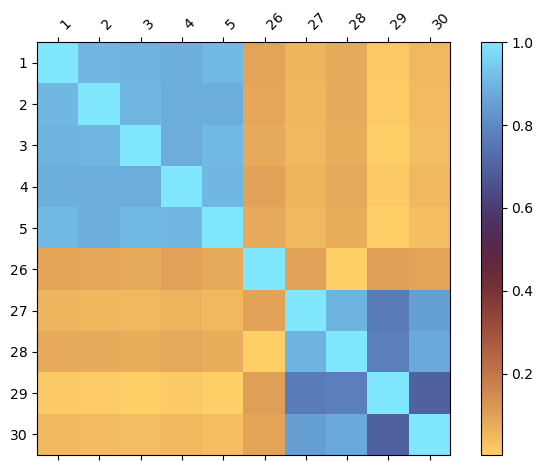

In [94]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 1.0])